# Boneyard Creek (USGS 03337000) — STIV sobre camara oblicua

**Prueba de concepto.** Mide la velocidad superficial del agua por STIV (Space-Time Image
Velocimetry) en un video de la estacion de aforo de Boneyard Creek en Urbana, Illinois. pyorc no se
importa en ningun momento: la rectificacion, la imagen espacio-temporal y el tensor de estructura
estan implementados aqui sobre OpenCV.

## Que hace distinto a este caso

Es el primero del workspace en el que **no hay geometria de ningun tipo**. El data release del USGS
(doi:10.5066/P9VZ6VYM) publica 61 videos y, para cada uno, el calado de escala `GH` y el caudal `Q`
del limnigrafo. Nada mas: ni puntos de control, ni ancho de canal, ni seccion transversal, ni
configuracion de camara.

| | Ngwerere | USGS SMC | **Boneyard** |
|---|---|---|---|
| Escala | 4 GCPs RTK | ancho conocido 1.8288 m | **ninguna** |
| Seccion | 27 puntos batimetricos | CSV de 13 estaciones | **ninguna** |
| Vista | oblicua | cenital | **oblicua** |
| Estabilizacion | en proceso | script previo, 1.1 GB | **no hace falta** |
| Validacion | 1 valor publicado | 1 aforo ADV | **61 pares GH-Q** |

Sin escala no hay metros y sin seccion no hay caudal. Este notebook **no calcula caudal**: llega a
velocidad superficial en unidades afines, que es lo que la geometria disponible permite sostener.

## La idea que hace que eso siga siendo util

La camara es oblicua, asi que la escala cambia con la fila de la imagen y no se puede aplicar el
esquema del caso SMC (cenital, una sola escala en mm/px). Hay que rectificar. Y para rectificar sin
puntos de control se usa el **punto de fuga longitudinal**, que las hiladas de mamposteria de los
dos muros determinan sin ambiguedad.

Lo importante es lo que basta con eso:

> Una homografia que lleva el horizonte correcto del plano de agua al infinito es, respecto de ese
> plano, una **afinidad**. Una afinidad escala por igual todas las longitudes de una misma
> direccion. Como el flujo es longitudinal en todo el canal, **la velocidad sale correcta salvo una
> unica constante global**, sea cual sea la focal que se suponga.

De ahi que la focal sea cosmetica y que el resultado se reporte en *alturas de camara por segundo*:
una unidad estable, que no depende ni de la resolucion de salida ni de los fps, y que se convierte
en m/s multiplicando por la altura real de la camara sobre el agua el dia que se conozca.

## Constantes compartidas con `video_velocidad.py`

El script que genera el video de la Parte 8 repite esta geometria. Si se cambia una, hay que
cambiarla en los dos sitios.

| Constante | Valor |
|---|---|
| `V1` | (653.0, -30.9) px |
| `FOCAL` | 640 px (cosmetica) |
| `XMIN`, `XMAX` | -2.10, 1.85 alturas de camara |
| `YMIN`, `YMAX` | 0.40, 2.80 |
| `ESC` | 450 px por altura de camara |
| `DS`, `N_EST` | 5 px, 21 estaciones |
| `BLOQUE`, `SOLAPE` | 48 px, 50% |
| `COH_MIN`, `CONTRASTE_MIN`, `COBERTURA_MIN` | 0.40, 1.5, 0.60 |

## Como se ejecuta

Desde **esta carpeta**, de arriba abajo. Todas las rutas son relativas al directorio del notebook y
la Parte 0 imprime `FALTA` si el kernel arranco en otro sitio. Los videos no estan en el workspace:
son 4.7 GB del data release y viven donde se descomprimieron (`DIR_VIDEOS`, ruta absoluta).

## Parte 0 — Rutas

Todo lo que se escribe va a `salidas/`. Se usan dos videos distintos y conviene entender por que:

- `ARCHIVO_CALIB` es de **aguas bajas**, con los dos muros al descubierto. De ahi sale la geometria.
- `ARCHIVO_VIDEO` es el que se mide: el caudal **mas alto con luz diurna** de todo el dataset.

Calibrar en uno y medir en otro es legitimo, y no es un atajo: el horizonte de un plano horizontal
no depende de la altura del plano. Subir el nivel del agua cambia la constante global de escala,
que aqui es desconocida de todos modos, pero **no cambia el horizonte**, que es lo unico que la
rectificacion necesita.

In [1]:
import json
import os
import subprocess
import sys
import time

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import benchmark

# los videos son el data release del USGS (4.7 GB), fuera del workspace
DIR_DATOS = r'C:\Users\Sergio\Desktop\Boneyardcreek'
DIR_VIDEOS = os.path.join(DIR_DATOS, 'boneyardcreek_video')
ARCHIVO_REGISTRO = os.path.join(DIR_DATOS, 'boneyardcreek_video_records (2).csv')

# aguas bajas: los muros al descubierto, de aqui sale la geometria
ARCHIVO_CALIB = os.path.join(DIR_VIDEOS, '03337000_bullet_20180907-162000.mp4')
# el que se mide: mayor caudal diurno del dataset (GH 14.88 ft, Q 368 cfs)
ARCHIVO_VIDEO = os.path.join(DIR_VIDEOS, '03337000_bullet_20180610-082000.mp4')

DIR_SALIDA = 'salidas'
os.makedirs(DIR_SALIDA, exist_ok=True)
SALIDA_CONFIG = os.path.join(DIR_SALIDA, 'config_stiv.json')
SALIDA_PERFIL = os.path.join(DIR_SALIDA, 'perfil_transversal.csv')
SALIDA_TRIAJE = os.path.join(DIR_SALIDA, 'triaje_videos.csv')
SALIDA_RECURSOS = os.path.join(DIR_SALIDA, 'benchmark_recursos.csv')
SALIDA_RESUMEN = os.path.join(DIR_SALIDA, 'velocidad_resumen.csv')

print(f'directorio de trabajo: {os.getcwd()}')
for nombre, ruta in [('registro', ARCHIVO_REGISTRO), ('video calibracion', ARCHIVO_CALIB),
                     ('video a medir', ARCHIVO_VIDEO), ('benchmark.py', 'benchmark.py')]:
    print(f'  {nombre:20s} {"OK  " if os.path.exists(ruta) else "FALTA"} {ruta}')

directorio de trabajo: C:\Users\Sergio\Documents\test_pyorc\analisis_boneyard_stiv
  registro             OK   C:\Users\Sergio\Desktop\Boneyardcreek\boneyardcreek_video_records (2).csv
  video calibracion    OK   C:\Users\Sergio\Desktop\Boneyardcreek\boneyardcreek_video\03337000_bullet_20180907-162000.mp4
  video a medir        OK   C:\Users\Sergio\Desktop\Boneyardcreek\boneyardcreek_video\03337000_bullet_20180610-082000.mp4
  benchmark.py         OK   benchmark.py


## Parte 1 — El dataset y por que este video

61 videos, uno cada 5 minutos durante crecidas con `GH` por encima de 12 pies. Cada uno trae su
caudal. Pero la camara pasa a infrarrojo de noche, y en modo nocturno esta desenfocada, en blanco y
negro y con gotas en la lente: esos videos son ilegibles.

El triaje mide brillo, saturacion y nitidez de un fotograma central de cada uno. La saturacion es
el discriminante limpio: el modo IR nocturno sale en gris, con saturacion casi nula.

In [2]:
reg = pd.read_csv(ARCHIVO_REGISTRO)
reg['archivo'] = reg['filepath'].str.replace('\\', '/', regex=False).str.rsplit('/', n=1).str[-1]
print(f'{len(reg)} videos, GH {reg.GH.min()}-{reg.GH.max()} ft, Q {reg.Q.min()}-{reg.Q.max()} cfs')

ficha = reg[reg.archivo == os.path.basename(ARCHIVO_VIDEO)].iloc[0]
print(f'\nvideo a medir: {ficha.archivo}')
print(f'  {ficha.date} {ficha.time}   GH = {ficha.GH} ft   Q = {ficha.Q} cfs')

61 videos, GH 12.04-15.88 ft, Q 89.0-470.0 cfs

video a medir: 03337000_bullet_20180610-082000.mp4
  6/10/2018 8:20:00   GH = 14.88 ft   Q = 368.0 cfs


In [3]:
# Triaje de los 61. Una pasada, un fotograma por video.
with benchmark.medir('Parte 1: triaje de los 61 videos', n_frames=len(reg)):
    filas = []
    for _, r in reg.iterrows():
        cap = cv2.VideoCapture(os.path.join(DIR_VIDEOS, r.archivo))
        n, fps = cap.get(cv2.CAP_PROP_FRAME_COUNT), cap.get(cv2.CAP_PROP_FPS)
        cap.set(cv2.CAP_PROP_POS_FRAMES, n // 2)
        ok, fr = cap.read()
        cap.release()
        if not ok:
            continue
        hsv = cv2.cvtColor(fr, cv2.COLOR_BGR2HSV)
        gris = cv2.cvtColor(fr, cv2.COLOR_BGR2GRAY)
        filas.append(dict(archivo=r.archivo, hora=r.time, GH=r.GH, Q=r.Q,
                          n_frames=int(n), fps=round(fps, 2),
                          brillo=round(gris.mean(), 1),
                          saturacion=round(hsv[:, :, 1].mean(), 1),
                          nitidez=round(cv2.Laplacian(gris, cv2.CV_64F).var(), 1)))

triaje = pd.DataFrame(filas)
# >>> AJUSTABLE <<< umbrales del triaje. Separan modo diurno de modo IR nocturno;
# la saturacion es el discriminante, el brillo solo descarta los muy oscuros.
triaje['utilizable'] = (triaje.saturacion > 20) & (triaje.brillo > 40)
triaje.to_csv(SALIDA_TRIAJE, index=False)

util = triaje[triaje.utilizable]
print(f'{triaje.utilizable.sum()} de {len(triaje)} utilizables')
print(f'  rango de Q utilizable : {util.Q.min()} - {util.Q.max()} cfs')
print(f'  rango de Q descartado : {triaje[~triaje.utilizable].Q.min()} - '
      f'{triaje[~triaje.utilizable].Q.max()} cfs')
print('\nlos dos caudales mas altos del dataset son nocturnos y se pierden:')
print(triaje.nlargest(4, 'Q')[['archivo', 'hora', 'Q', 'saturacion', 'utilizable']]
      .to_string(index=False))

  [bench] Parte 1: triaje de los 61 videos: 20.5 s | CPU 90.2 s (4.4 nucleos) | RAM pico 217 MB
50 de 61 utilizables
  rango de Q utilizable : 94.1 - 368.0 cfs
  rango de Q descartado : 89.0 - 470.0 cfs

los dos caudales mas altos del dataset son nocturnos y se pierden:
                            archivo     hora     Q  saturacion  utilizable
03337000_bullet_20180815-201500.mp4 20:15:00 470.0         0.0       False
03337000_bullet_20180509-201500.mp4 20:15:00 446.0         0.0       False
03337000_bullet_20180610-082000.mp4  8:20:00 368.0        53.6        True
03337000_bullet_20180820-201000.mp4 20:10:00 344.0         0.0       False


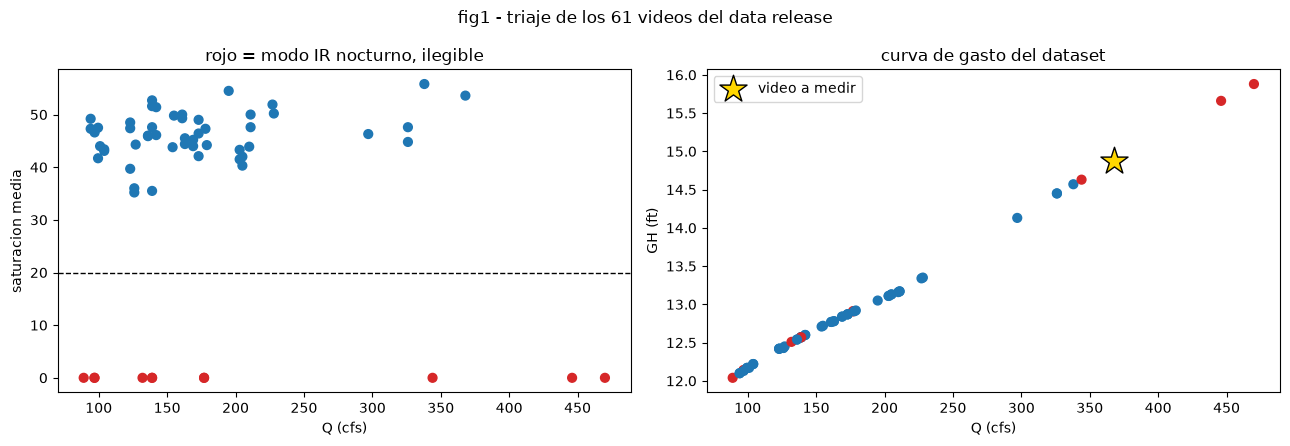

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(triaje.Q, triaje.saturacion, c=np.where(triaje.utilizable, 'tab:blue', 'tab:red'), s=40)
ax[0].axhline(20, ls='--', c='k', lw=1)
ax[0].set_xlabel('Q (cfs)'); ax[0].set_ylabel('saturacion media')
ax[0].set_title('rojo = modo IR nocturno, ilegible')
ax[1].scatter(triaje.Q, triaje.GH, c=np.where(triaje.utilizable, 'tab:blue', 'tab:red'), s=40)
ax[1].scatter([ficha.Q], [ficha.GH], marker='*', s=420, c='gold', ec='k', zorder=5,
              label='video a medir')
ax[1].set_xlabel('Q (cfs)'); ax[1].set_ylabel('GH (ft)'); ax[1].legend()
ax[1].set_title('curva de gasto del dataset')
fig.suptitle('fig1 - triaje de los 61 videos del data release')
fig.tight_layout(); fig.savefig(os.path.join(DIR_SALIDA, 'fig1_triaje.png'), dpi=110)
plt.show()

### La camara no se mueve

Antes de decidir si hace falta estabilizar, se mide. Dos escalas distintas: la deriva **entre
fechas** (¿vale una sola calibracion para toda la serie?) y la vibracion **dentro** del video (¿la
pasarela tiembla al pasar gente?). Ambas por correlacion de fase sobre un trozo de mamposteria que
no se moja ni en la mayor avenida.

In [5]:
# >>> AJUSTABLE <<< trozo de muro seco incluso a GH 14.88, usado como referencia fija
ROI_MURO = (slice(30, 330), slice(30, 300))


def _norm(a):
    a = a.astype(np.float32)
    return (a - a.mean()) / (a.std() + 1e-6)


def _parche(ruta, idx=None):
    cap = cv2.VideoCapture(ruta)
    cap.set(cv2.CAP_PROP_POS_FRAMES,
            cap.get(cv2.CAP_PROP_FRAME_COUNT) // 2 if idx is None else idx)
    ok, fr = cap.read()
    cap.release()
    return _norm(cv2.cvtColor(fr, cv2.COLOR_BGR2GRAY)[ROI_MURO]) if ok else None


# deriva entre fechas: un video diurno por fecha, todos contra el primero
fechas = (triaje[triaje.utilizable].assign(fecha=lambda d: d.archivo.str.split('_').str[2].str[:8])
          .drop_duplicates('fecha').sort_values('fecha'))
ref, deriva = None, []
for _, r in fechas.iterrows():
    p = _parche(os.path.join(DIR_VIDEOS, r.archivo))
    if p is None:
        continue
    if ref is None:
        ref = p
        continue
    (dx, dy), _ = cv2.phaseCorrelate(ref, p)
    deriva.append((r.fecha, dx, dy))
deriva = pd.DataFrame(deriva, columns=['fecha', 'dx', 'dy'])
print(f'deriva entre fechas ({len(deriva)+1} fechas, {deriva.fecha.iloc[0]}...{deriva.fecha.iloc[-1]}):')
print(f'  |dx| max {deriva.dx.abs().max():.2f} px    |dy| max {deriva.dy.abs().max():.2f} px')

# vibracion dentro del video que se va a medir
cap = cv2.VideoCapture(ARCHIVO_VIDEO)
cap.set(cv2.CAP_PROP_POS_FRAMES, 100)
prev, vib = None, []
for _ in range(60):
    ok, fr = cap.read()
    if not ok:
        break
    g = _norm(cv2.cvtColor(fr, cv2.COLOR_BGR2GRAY)[ROI_MURO])
    if prev is not None:
        vib.append(cv2.phaseCorrelate(prev, g)[0])
    prev = g
cap.release()
vib = np.abs(np.array(vib))
print(f'\nvibracion entre fotogramas consecutivos:')
print(f'  |dx| mediana {np.median(vib[:,0]):.3f} px, max {vib[:,0].max():.3f} px')
print(f'  |dy| mediana {np.median(vib[:,1]):.3f} px, max {vib[:,1].max():.3f} px')
print('\n-> ni deriva ni vibracion relevantes: este caso NO necesita estabilizacion,')
print('   a diferencia del SMC, que exigia 25.6 px de correccion y un .mkv de 1.1 GB.')

deriva entre fechas (24 fechas, 20170711...20181231):
  |dx| max 0.76 px    |dy| max 1.29 px



vibracion entre fotogramas consecutivos:
  |dx| mediana 0.022 px, max 0.054 px
  |dy| mediana 0.059 px, max 0.099 px

-> ni deriva ni vibracion relevantes: este caso NO necesita estabilizacion,
   a diferencia del SMC, que exigia 25.6 px de correccion y un .mkv de 1.1 GB.


## Parte 2 — Geometria: punto de fuga y rectificacion

Las hiladas de mamposteria de los dos muros son paralelas al eje del canal, asi que sus imagenes
concurren en el punto de fuga longitudinal **V1**. Cada segmento define una recta homogenea
`l = p1 x p2`; el punto de fuga es el que cumple `l.x = 0` para todas. Se resuelve con RANSAC,
porque muchos segmentos detectados son piedras sueltas o textura del agua, no hiladas.

Que los segmentos de **los dos muros, uno a cada lado**, apunten al mismo sitio es la comprobacion
de que el punto es real y no un artefacto de un solo muro.

Las juntas verticales tambien se intentaron, para sacar el punto de fuga vertical y medir el
balanceo. No funciona: dan un punto absurdo dentro de la imagen, porque lo que LSD detecta como
"vertical" son cantos de piedra irregulares. Se asume **balanceo nulo**, que es razonable para una
camara atornillada bajo una pasarela horizontal, y queda como la hipotesis geometrica del caso.

In [6]:
# >>> AJUSTABLE <<< geometria de la escena
MUROS = [(0, 0, 345, 480), (890, 40, 1190, 500)]   # regiones con rectas fiables
LARGO_MIN = 25                                     # longitud minima de segmento, px
V1_FIJO = (653.0, -30.9)                           # resultado congelado; None para reestimar
FOCAL = 640.0                                      # cosmetica: solo cambia el aspecto
ANCHO_IMG, ALTO_IMG = 1280, 720

cap = cv2.VideoCapture(ARCHIVO_CALIB)
cap.set(cv2.CAP_PROP_POS_FRAMES, cap.get(cv2.CAP_PROP_FRAME_COUNT) // 2)
_, frame_calib = cap.read()
cap.release()

segs = cv2.createLineSegmentDetector().detect(
    cv2.cvtColor(frame_calib, cv2.COLOR_BGR2GRAY))[0].reshape(-1, 4)
cx, cy = (segs[:, 0] + segs[:, 2]) / 2, (segs[:, 1] + segs[:, 3]) / 2
dentro = np.zeros(len(segs), bool)
for x0, y0, x1, y1 in MUROS:
    dentro |= (cx >= x0) & (cx < x1) & (cy >= y0) & (cy < y1)
largo = np.hypot(segs[:, 2] - segs[:, 0], segs[:, 3] - segs[:, 1])
segs = segs[dentro & (largo > LARGO_MIN)]
ang = np.degrees(np.arctan2(segs[:, 3] - segs[:, 1], segs[:, 2] - segs[:, 0])) % 180
hiladas = segs[(ang < 45) | (ang > 135)]
print(f'{len(segs)} segmentos en los muros, {len(hiladas)} con orientacion de hilada')


def punto_de_fuga(s, umbral=2.5, iters=3000, semilla=0):
    rng = np.random.default_rng(semilla)
    p1 = np.c_[s[:, 0], s[:, 1], np.ones(len(s))]
    p2 = np.c_[s[:, 2], s[:, 3], np.ones(len(s))]
    l = np.cross(p1, p2)
    l /= np.linalg.norm(l[:, :2], axis=1, keepdims=True)
    L = np.hypot(s[:, 2] - s[:, 0], s[:, 3] - s[:, 1])
    mejor, n_mejor = None, -1
    for _ in range(iters):
        i, j = rng.choice(len(l), 2, replace=False)
        v = np.cross(l[i], l[j])
        if abs(v[2]) < 1e-9:
            continue
        # el umbral se afloja para segmentos cortos: un mismo error angular
        # desplaza mas el punto de fuga cuanto mas corto es el segmento
        inl = np.abs(l @ v) / abs(v[2]) < umbral * (200.0 / np.maximum(L, 25))
        if inl.sum() > n_mejor:
            mejor, n_mejor = inl, inl.sum()
    _, _, vt = np.linalg.svd(l[mejor] * L[mejor, None])
    v = vt[-1] / vt[-1][2]
    return v[:2], mejor


V1_est, inliers = punto_de_fuga(hiladas)
print(f'V1 estimado = ({V1_est[0]:.1f}, {V1_est[1]:.1f}) con {inliers.sum()} inliers')
V1 = np.array(V1_FIJO if V1_FIJO is not None else V1_est)
print(f'V1 en uso   = ({V1[0]:.1f}, {V1[1]:.1f})')

88 segmentos en los muros, 56 con orientacion de hilada


V1 estimado = (653.0, -30.9) con 17 inliers
V1 en uso   = (653.0, -30.9)


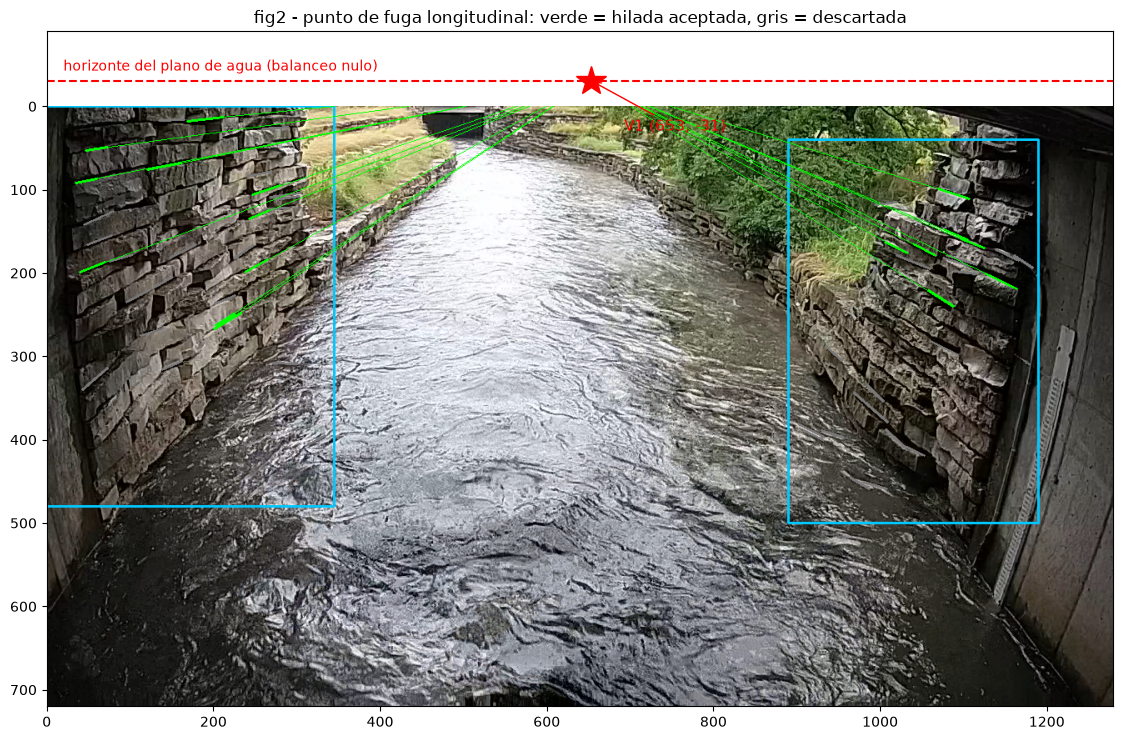

In [7]:
vis = frame_calib.copy()
for x0, y0, x1, y1 in MUROS:
    cv2.rectangle(vis, (x0, y0), (x1, y1), (255, 200, 0), 2)
for k, (x1, y1, x2, y2) in enumerate(hiladas):
    c = (0, 255, 0) if inliers[k] else (120, 120, 120)
    cv2.line(vis, (int(x1), int(y1)), (int(x2), int(y2)), c, 2)
    if inliers[k]:
        cv2.line(vis, (int((x1 + x2) / 2), int((y1 + y2) / 2)),
                 (int(V1[0]), int(np.clip(V1[1], -3000, 3000))), c, 1)

fig, ax = plt.subplots(figsize=(13, 7.5))
ax.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
ax.plot(V1[0], V1[1], 'r*', ms=22, clip_on=False)
ax.axhline(V1[1], color='red', ls='--', lw=1.5)
ax.annotate(f'V1 ({V1[0]:.0f}, {V1[1]:.0f})', (V1[0], V1[1]), xytext=(V1[0] + 40, V1[1] + 60),
            color='red', fontsize=11, arrowprops=dict(color='red', arrowstyle='->'))
ax.text(20, V1[1] - 12, 'horizonte del plano de agua (balanceo nulo)', color='red', fontsize=10)
ax.set_ylim(720, -90); ax.set_xlim(0, 1280)
ax.set_title('fig2 - punto de fuga longitudinal: verde = hilada aceptada, gris = descartada')
fig.tight_layout(); fig.savefig(os.path.join(DIR_SALIDA, 'fig2_punto_fuga.png'), dpi=110)
plt.show()

### De V1 a la homografia

Con balanceo nulo el horizonte es la horizontal por V1, y de `y_h = cy - f*tan(theta)` sale el
cabeceo. La componente x de V1 da la guinada, que se compensa para que el canal quede vertical en
la salida. La altura de camara se fija a 1: es la unidad en la que quedara todo.

**La verificacion esta en la figura, no en un numero**: si el horizonte fuera erroneo o la
distorsion de lente importara, el canal saldria en abanico o combado. Que salga como una banda
recta de anchura constante es lo que valida la rectificacion entera.

In [8]:
# >>> AJUSTABLE <<< recorte del plano de agua, en alturas de camara
XMIN, XMAX = -2.10, 1.85     # transversal: alcanza los dos muros
YMIN, YMAX = 0.40, 2.80      # longitudinal: solo el campo cercano. Mas arriba, cerca
                             # del horizonte, un pixel de imagen cubre tanto terreno
                             # que el remuestreo borra la textura y no hay que medir.
ESC = 450.0                  # px de salida por altura de camara


def homografia(v1, focal, xmin, ymax, esc):
    cxi, cyi = ANCHO_IMG / 2, ALTO_IMG / 2
    theta = np.arctan((cyi - v1[1]) / focal)
    K = np.array([[focal, 0, cxi], [0, focal, cyi], [0, 0, 1.0]])
    R = np.array([[1, 0, 0],
                  [0, -np.sin(theta), -np.cos(theta)],
                  [0, np.cos(theta), -np.sin(theta)]])
    g2i = K @ np.column_stack([R[:, 0], R[:, 1], [0, np.cos(theta), np.sin(theta)]])
    d = R.T @ np.linalg.inv(K) @ np.array([v1[0], v1[1], 1.0])
    psi = np.arctan2(d[0], d[1])
    rot = np.array([[np.cos(psi), np.sin(psi), 0],
                    [-np.sin(psi), np.cos(psi), 0], [0, 0, 1.0]])
    S = np.array([[esc, 0, -xmin * esc], [0, -esc, ymax * esc], [0, 0, 1.0]])
    return S @ np.linalg.inv(g2i @ np.linalg.inv(rot)), np.degrees(theta), np.degrees(psi)


I2O, CABECEO, GUINADA = homografia(V1, FOCAL, XMIN, YMAX, ESC)
OW, OH = int((XMAX - XMIN) * ESC), int((YMAX - YMIN) * ESC)
print(f'cabeceo {CABECEO:.2f} grados, guinada {GUINADA:.2f} grados')
print(f'salida rectificada {OW}x{OH} px')

cap = cv2.VideoCapture(ARCHIVO_VIDEO)
cap.set(cv2.CAP_PROP_POS_FRAMES, 60)
_, frame_medida = cap.read()
cap.release()
rect_calib = cv2.warpPerspective(frame_calib, I2O, (OW, OH))
rect_medida = cv2.warpPerspective(frame_medida, I2O, (OW, OH))
# lo que la camara no llega a ver: la rectificacion arrastra esas zonas igual
COBERTURA_IMG = cv2.warpPerspective(np.full((ALTO_IMG, ANCHO_IMG), 255, np.uint8), I2O, (OW, OH))

cabeceo 31.42 grados, guinada 0.99 grados
salida rectificada 1777x1080 px


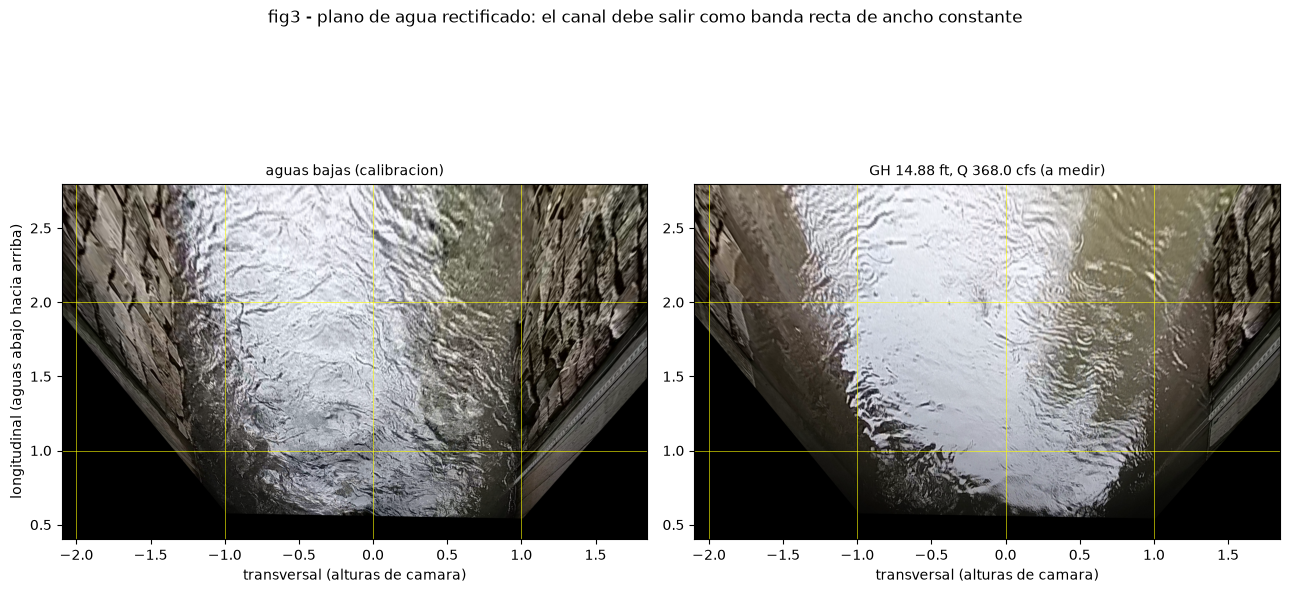

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 7))
for a, im, t in [(ax[0], rect_calib, f'aguas bajas (calibracion)'),
                 (ax[1], rect_medida, f'GH {ficha.GH} ft, Q {ficha.Q} cfs (a medir)')]:
    a.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB),
             extent=[XMIN, XMAX, YMIN, YMAX], aspect='equal')
    a.set_xlabel('transversal (alturas de camara)')
    a.set_title(t, fontsize=10)
    for g in np.arange(np.ceil(XMIN), XMAX, 1.0):
        a.axvline(g, color='yellow', lw=0.7, alpha=0.6)
    for g in np.arange(np.ceil(YMIN), YMAX, 1.0):
        a.axhline(g, color='yellow', lw=0.7, alpha=0.6)
ax[0].set_ylabel('longitudinal (aguas abajo hacia arriba)')
fig.suptitle('fig3 - plano de agua rectificado: el canal debe salir como banda recta de ancho constante')
fig.tight_layout(); fig.savefig(os.path.join(DIR_SALIDA, 'fig3_rectificado.png'), dpi=110)
plt.show()

## Parte 3 — La imagen espacio-temporal

Para cada estacion transversal se muestrea una linea longitudinal cada `DS` px y se apilan esas
lineas en el tiempo. La pendiente de las trazas es la velocidad.

`DS` no se teclea, se deriva. Con una particula a `v` px/fotograma, avanza `v/DS` columnas por
fila, asi que el angulo de la traza desde el eje de columnas cumple `tan(theta) = DS/v`. A 45
grados el error angular pesa lo menos posible, porque `du/u = dtheta/(sin.cos)` es minimo ahi. Se
mide `v` por correlacion de fase y se elige `DS` para caer cerca de 45.

Antes de diezmar hay que aplicar el antialias, `sigma = DS/2`. Es obligatorio, no opcional.

In [10]:
# >>> AJUSTABLE <<< muestreo del STI
N_EST = 21          # estaciones transversales
N_FRAMES = 250      # fotogramas para el perfil estacionario de las Partes 4 y 5
                    # (la Parte 8 usa el video entero en ventanas deslizantes)

cap = cv2.VideoCapture(ARCHIVO_VIDEO)
FPS = cap.get(cv2.CAP_PROP_FPS)
N_TOTAL = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

# desplazamiento real por fotograma, para elegir DS
cap.set(cv2.CAP_PROP_POS_FRAMES, 100)
prev, desp = None, []
for _ in range(40):
    ok, fr = cap.read()
    if not ok:
        break
    r = cv2.warpPerspective(cv2.cvtColor(fr, cv2.COLOR_BGR2GRAY), I2O, (OW, OH))
    banda = _norm(r[int(OH * 0.65):int(OH * 0.85), int(OW * 0.25):int(OW * 0.75)])
    if prev is not None:
        desp.append(cv2.phaseCorrelate(prev, banda)[0][1])
    prev = banda
cap.release()
V_MEDIDA = float(np.median(desp))
print(f'{N_TOTAL} fotogramas a {FPS:.2f} fps ({N_TOTAL/FPS:.1f} s)')
print(f'desplazamiento medido por correlacion de fase: {V_MEDIDA:+.2f} px de salida por fotograma')
print(f'  (signo negativo = el agua se aleja de la camara; verificado con un desplazamiento conocido)')

DS = 5              # >>> AJUSTABLE <<< paso espacial del STI
print(f'\nDS = {DS} -> trazas a {np.degrees(np.arctan(DS/abs(V_MEDIDA))):.1f} grados '
      f'(45 seria el optimo)')
print(f'  con DS = 1 caerian a {np.degrees(np.arctan(1/abs(V_MEDIDA))):.1f} grados, '
      f'donde el mismo error angular pesa '
      f'{(np.sin(np.arctan(DS/abs(V_MEDIDA)))*np.cos(np.arctan(DS/abs(V_MEDIDA))))/(np.sin(np.arctan(1/abs(V_MEDIDA)))*np.cos(np.arctan(1/abs(V_MEDIDA)))):.1f}x mas')

867 fotogramas a 22.42 fps (38.7 s)
desplazamiento medido por correlacion de fase: -4.71 px de salida por fotograma
  (signo negativo = el agua se aleja de la camara; verificado con un desplazamiento conocido)

DS = 5 -> trazas a 46.7 grados (45 seria el optimo)
  con DS = 1 caerian a 12.0 grados, donde el mismo error angular pesa 2.5x mas


In [11]:
COLS = (np.linspace(0.04, 0.96, N_EST) * OW).astype(int)
FILAS = np.arange(0, OH, DS)
X_SUELO = XMIN + COLS / ESC
COBERTURA = (COBERTURA_IMG[np.ix_(FILAS, COLS)].T > 128).astype(np.float32)

with benchmark.medir('Parte 3: construir el STI', n_frames=N_FRAMES, ds=DS, n_est=N_EST):
    cap = cv2.VideoCapture(ARCHIVO_VIDEO)
    cap.set(cv2.CAP_PROP_POS_FRAMES, 60)
    STI = np.zeros((N_FRAMES, N_EST, len(FILAS)), np.float32)
    for k in range(N_FRAMES):
        ok, fr = cap.read()
        if not ok:
            STI = STI[:k]
            break
        r = cv2.warpPerspective(cv2.cvtColor(fr, cv2.COLOR_BGR2GRAY), I2O, (OW, OH),
                                flags=cv2.INTER_LINEAR)
        STI[k] = cv2.GaussianBlur(r, (0, 0), DS / 2)[np.ix_(FILAS, COLS)].T
    cap.release()

print(f'STI: {STI.shape[0]} fotogramas x {N_EST} estaciones x {len(FILAS)} muestras')

  [bench] Parte 3: construir el STI: 6.0 s | CPU 43.0 s (7.2 nucleos) | RAM pico 287 MB
STI: 250 fotogramas x 21 estaciones x 216 muestras


### Normalizacion temporal

El STI crudo tiene una franja vertical quemada en el centro: el reflejo especular del cielo. No
tiene textura, asi que los bloques que caen ahi no aportan trazas y hunden la coherencia.

Como el reflejo es **estatico en el espacio** y solo el agua cambia, restar a cada posicion su
media temporal y dividir por su desviacion lo elimina por construccion. Sin ningun parametro. Las
posiciones saturadas (desviacion casi nula) se anulan en vez de amplificarse.

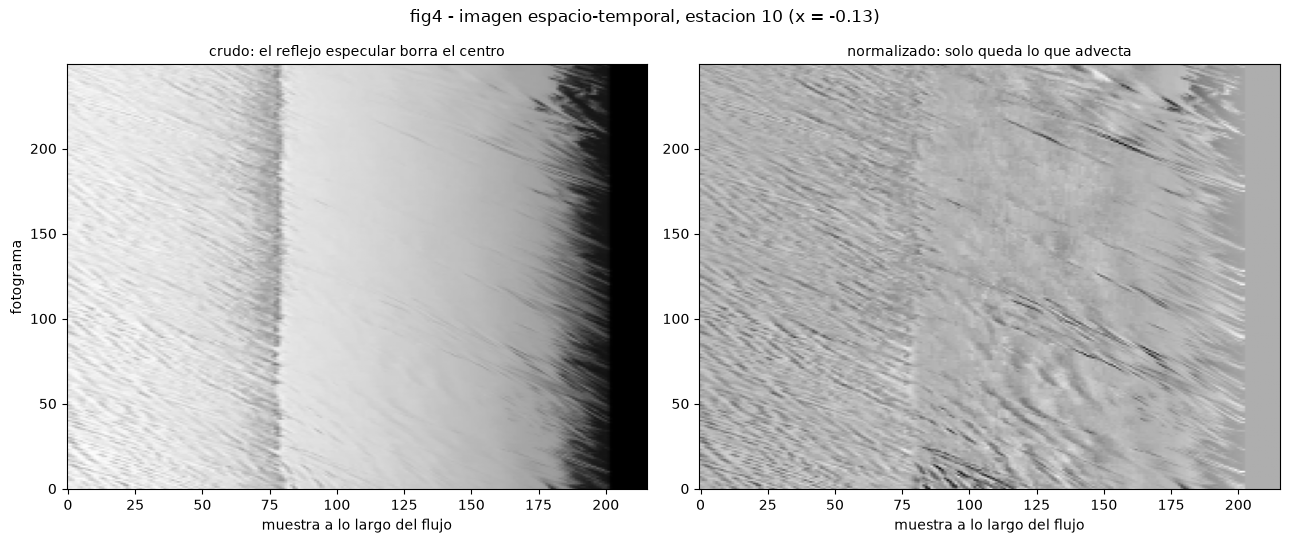

In [12]:
MU, SD = STI.mean(0), STI.std(0)
CONTRASTE = np.median(SD, axis=1)          # por estacion: cuanto cambia con el tiempo
STIN = (STI - MU) / np.maximum(SD, 1e-3)
STIN[:, SD < 1.0] = 0.0                    # saturado: sin informacion, no ruido amplificado

e_dem = N_EST // 2
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
for a, im, t in [(ax[0], STI[:, e_dem, :], 'crudo: el reflejo especular borra el centro'),
                 (ax[1], STIN[:, e_dem, :], 'normalizado: solo queda lo que advecta')]:
    a.imshow(im, cmap='gray', aspect='auto', origin='lower')
    a.set_xlabel('muestra a lo largo del flujo'); a.set_title(t, fontsize=10)
ax[0].set_ylabel('fotograma')
fig.suptitle(f'fig4 - imagen espacio-temporal, estacion {e_dem} (x = {X_SUELO[e_dem]:+.2f})')
fig.tight_layout(); fig.savefig(os.path.join(DIR_SALIDA, 'fig4_sti.png'), dpi=110)
plt.show()

## Parte 4 — Tensor de estructura

La orientacion dominante de las trazas es el autovector del autovalor **menor** del tensor: la
direccion a lo largo de la cual la intensidad varia menos.

Se calcula por bloques con 50% de solape y se combinan con mediana ponderada por coherencia. Un
tensor global dejaria que un unico parche brillante dictara la respuesta de toda la estacion.

In [13]:
# >>> AJUSTABLE <<< tensor
BLOQUE = 48        # lado del bloque, px. Debe caber en la ventana temporal de la Parte 8
SOLAPE = 0.5


def tensor(img, cobertura_est):
    """Devuelve (velocidad en px de salida por fotograma, coherencia mediana).

    tan(theta) = DS/v con theta medido desde el eje de columnas, de donde v = DS/tan(theta).
    """
    if min(img.shape) < BLOQUE:
        return np.nan, 0.0
    gy, gx = np.gradient(img.astype(np.float32))
    k = (BLOQUE, BLOQUE)
    jxx = cv2.boxFilter(gx * gx, -1, k, normalize=False)
    jyy = cv2.boxFilter(gy * gy, -1, k, normalize=False)
    jxy = cv2.boxFilter(gx * gy, -1, k, normalize=False)
    h, p = BLOQUE // 2, max(int(BLOQUE * (1 - SOLAPE)), 1)
    ii, jj = np.meshgrid(np.arange(h, img.shape[0] - h, p),
                         np.arange(h, img.shape[1] - h, p), indexing='ij')
    a, b, c = jxx[ii, jj], jyy[ii, jj], jxy[ii, jj]
    tr = a + b
    val = (cobertura_est[jj] > 0.99) & (tr > 1e-9)   # bloques fuera de campo, fuera
    if val.sum() < 2:
        return np.nan, 0.0
    a, b, c, tr = a[val], b[val], c[val], tr[val]
    coh = (np.sqrt(np.maximum((a - b) ** 2 + 4 * c * c, 0.0)) / tr) ** 2
    ang = 0.5 * np.arctan2(2 * c, a - b) + np.pi / 2
    o = np.argsort(ang)
    ang, coh = ang[o], coh[o]
    ac = np.cumsum(coh)
    th = ang[np.searchsorted(ac, ac[-1] / 2)]        # mediana ponderada por coherencia
    tn = np.tan(th)
    return (float(DS / tn) if abs(tn) > 1e-6 else np.nan), float(np.median(coh))


with benchmark.medir('Parte 4: tensor de estructura', n_est=N_EST, bloque=BLOQUE):
    V_PX = np.full(N_EST, np.nan)
    COH = np.zeros(N_EST)
    for e in range(N_EST):
        V_PX[e], COH[e] = tensor(STIN[:, e, :], COBERTURA[e])

# a unidades de suelo por segundo: estable frente a ESC y a los fps, aunque no metrica
V_SUELO = V_PX * FPS / ESC
print(pd.DataFrame({'x_suelo': X_SUELO.round(3), 'cobertura': COBERTURA.mean(1).round(2),
                    'contraste': CONTRASTE.round(2), 'coherencia': COH.round(3),
                    'v_px_frame': V_PX.round(2), 'v_suelo_s': V_SUELO.round(4)}).to_string())

  [bench] Parte 4: tensor de estructura: 0.1 s | CPU 0.1 s (1.2 nucleos) | RAM pico 279 MB
    x_suelo  cobertura  contraste  coherencia  v_px_frame  v_suelo_s
0    -1.942       0.45   0.000000       0.735       -0.01    -0.0006
1    -1.762       0.54   0.940000       0.256       -0.94    -0.0466
2    -1.580       0.63   1.980000       0.204       -4.27    -0.2125
3    -1.398       0.72   5.490000       0.467       -5.37    -0.2675
4    -1.216       0.81  14.010000       0.457       -5.05    -0.2514
5    -1.036       0.91  20.219999       0.477       -4.87    -0.2427
6    -0.853       0.93  14.500000       0.596       -4.95    -0.2466
7    -0.671       0.93  10.290000       0.662       -5.43    -0.2707
8    -0.489       0.93   7.590000       0.629       -5.09    -0.2538
9    -0.309       0.94   7.630000       0.479       -4.96    -0.2470
10   -0.127       0.94   8.060000       0.488       -4.61    -0.2294
11    0.056       0.94   7.540000       0.645       -4.80    -0.2391
12    0.236 

## Parte 4b — Control de calidad, y una trampa que conviene entender

En el caso SMC el filtro era un umbral de coherencia a 0.70. **Aqui ese umbral no solo es
insuficiente: es contraproducente.**

Las estaciones que caen sobre los muros dan coherencia **0.99 con velocidad exactamente cero**, la
nota mas alta de toda la seccion. Y es correcto: una estructura estatica es una traza perfectamente
coherente de pendiente nula. Un umbral de coherencia no las rechaza, las aprueba.

El discriminante correcto no es la coherencia sino la **varianza temporal**: un muro no cambia. Y
el umbral no se elige a ojo, se lee de los datos — hay un hueco limpio de factor 5 entre lo
estatico y lo que fluye.

In [14]:
# >>> AJUSTABLE <<< control de calidad
COH_MIN = 0.40        # mas laxo que el 0.70 del caso SMC: aqui la textura es espuma
                      # fina, no el tracer grueso de aquel video
CONTRASTE_MIN = 1.5   # desviacion temporal minima; separa muro de agua
COBERTURA_MIN = 0.60  # laxo a proposito: el tensor ya descarta bloque a bloque lo que
                      # cae fuera de campo, y exigir mas solo pierde las estaciones
                      # junto a los muros, que son las que dan la forma del perfil

es_estatica = CONTRASTE < CONTRASTE_MIN
fuera_campo = COBERTURA.mean(1) < COBERTURA_MIN
baja_coh = COH < COH_MIN
ACEPTADA = ~(es_estatica | fuera_campo | baja_coh)

qc = pd.DataFrame({'x_suelo': X_SUELO.round(3), 'contraste': CONTRASTE.round(2),
                   'cobertura': COBERTURA.mean(1).round(2), 'coherencia': COH.round(3),
                   'v_suelo_s': V_SUELO.round(4), 'aceptada': ACEPTADA})
qc['motivo'] = ['' if a else ', '.join(
    [m for m, cond in [('muro (estatica)', es), ('fuera de campo', fc), ('coherencia baja', bc)] if cond])
    for a, es, fc, bc in zip(ACEPTADA, es_estatica, fuera_campo, baja_coh)]
print(qc.to_string())
print(f'\n{ACEPTADA.sum()} de {N_EST} estaciones aceptadas')
print(f'coherencia de las estaciones sobre muro: {COH[es_estatica].round(3)}  <- las mejores de todas')

    x_suelo  contraste  cobertura  coherencia  v_suelo_s  aceptada                                            motivo
0    -1.942   0.000000       0.45       0.735    -0.0006     False                   muro (estatica), fuera de campo
1    -1.762   0.940000       0.54       0.256    -0.0466     False  muro (estatica), fuera de campo, coherencia baja
2    -1.580   1.980000       0.63       0.204    -0.2125     False                                   coherencia baja
3    -1.398   5.490000       0.72       0.467    -0.2675      True                                                  
4    -1.216  14.010000       0.81       0.457    -0.2514      True                                                  
5    -1.036  20.219999       0.91       0.477    -0.2427      True                                                  
6    -0.853  14.500000       0.93       0.596    -0.2466      True                                                  
7    -0.671  10.290000       0.93       0.662    -0.2707      Tr

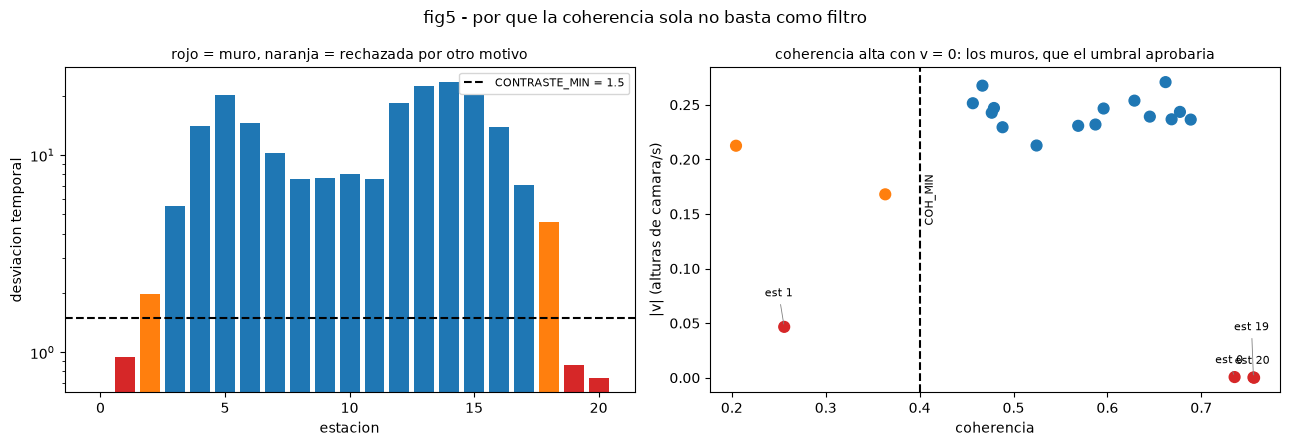

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
# un color por motivo: el rojo es "muro", que es el caso que la coherencia NO detecta
col = np.where(es_estatica, 'tab:red', np.where(ACEPTADA, 'tab:blue', 'tab:orange'))
ax[0].bar(range(N_EST), CONTRASTE, color=col)
ax[0].axhline(CONTRASTE_MIN, ls='--', c='k', label=f'CONTRASTE_MIN = {CONTRASTE_MIN}')
ax[0].set_yscale('log'); ax[0].set_xlabel('estacion'); ax[0].set_ylabel('desviacion temporal')
ax[0].set_title('rojo = muro, naranja = rechazada por otro motivo', fontsize=10)
ax[0].legend(fontsize=8)
ax[1].scatter(COH, np.abs(V_SUELO), c=col, s=60)
ax[1].axvline(COH_MIN, ls='--', c='k')
ax[1].text(COH_MIN + 0.005, ax[1].get_ylim()[1] * 0.5, 'COH_MIN', fontsize=8, rotation=90)
for k, e in enumerate(np.where(es_estatica)[0]):
    # alternar el desplazamiento: las estaciones de muro caen casi encima unas de otras
    ax[1].annotate(f'est {e}', (COH[e], abs(V_SUELO[e])), fontsize=8,
                   xytext=(-14, 10 + 12 * (k % 3)), textcoords='offset points',
                   arrowprops=dict(arrowstyle='-', lw=0.6, color='0.5'))
ax[1].set_xlabel('coherencia'); ax[1].set_ylabel('|v| (alturas de camara/s)')
ax[1].set_title('coherencia alta con v = 0: los muros, que el umbral aprobaria', fontsize=10)
fig.suptitle('fig5 - por que la coherencia sola no basta como filtro')
fig.tight_layout(); fig.savefig(os.path.join(DIR_SALIDA, 'fig5_control_calidad.png'), dpi=110)
plt.show()

## Parte 5 — Perfil transversal de velocidad superficial

Las estaciones rechazadas **no se rellenan**. En el caso SMC se interpolaban linealmente hasta los
ceros impuestos en los muros, y ese relleno costaba la mayor parte del error final. Aqui no hay
seccion, asi que no hay nada que integrar y rellenar solo serviria para inventar datos: se dejan
como huecos declarados.

In [16]:
perfil = pd.DataFrame({
    'estacion': np.arange(N_EST),
    'x_suelo': X_SUELO.round(4),
    'v_px_frame': V_PX.round(3),
    'v_suelo_s': np.abs(V_SUELO).round(5),
    'coherencia': COH.round(3),
    'contraste': CONTRASTE.round(2),
    'cobertura': COBERTURA.mean(1).round(2),
    'aceptada': ACEPTADA,
})
perfil.loc[~ACEPTADA, ['v_px_frame', 'v_suelo_s']] = np.nan
perfil.to_csv(SALIDA_PERFIL, index=False)

v_ok = np.abs(V_SUELO[ACEPTADA])
print(f'velocidad superficial sobre {ACEPTADA.sum()} estaciones aceptadas:')
print(f'  mediana  {np.median(v_ok):.4f} alturas de camara/s')
print(f'  q05-q95  {np.quantile(v_ok, 0.05):.4f} - {np.quantile(v_ok, 0.95):.4f}')
print(f'  maximo   {v_ok.max():.4f} en x = {X_SUELO[ACEPTADA][np.argmax(v_ok)]:+.2f}')

velocidad superficial sobre 15 estaciones aceptadas:
  mediana  0.2427 alturas de camara/s
  q05-q95  0.2244 - 0.2685
  maximo   0.2707 en x = -0.67


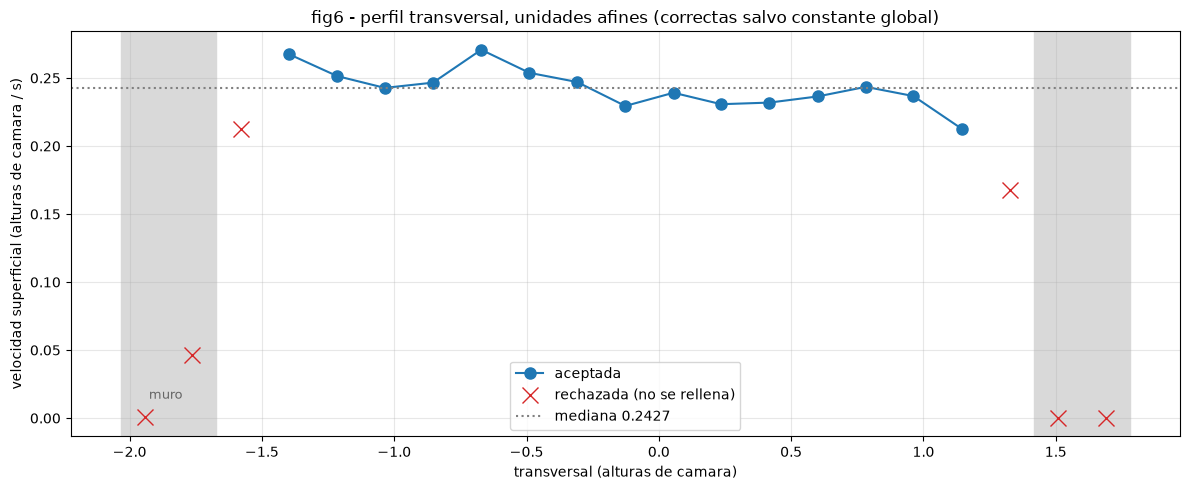

In [17]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(X_SUELO[ACEPTADA], np.abs(V_SUELO[ACEPTADA]), 'o-', color='tab:blue', ms=8,
        label='aceptada')
ax.plot(X_SUELO[~ACEPTADA], np.abs(V_SUELO[~ACEPTADA]), 'x', color='tab:red', ms=11,
        label='rechazada (no se rellena)')
ax.axhline(np.median(v_ok), ls=':', c='gray', label=f'mediana {np.median(v_ok):.4f}')
for e in np.where(es_estatica)[0]:
    ax.axvspan(X_SUELO[e] - 0.09, X_SUELO[e] + 0.09, color='0.85', zorder=0)
ax.text(X_SUELO[0], ax.get_ylim()[1] * 0.05, ' muro', color='0.4', fontsize=9)
ax.set_xlabel('transversal (alturas de camara)')
ax.set_ylabel('velocidad superficial (alturas de camara / s)')
ax.set_title('fig6 - perfil transversal, unidades afines (correctas salvo constante global)')
ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(os.path.join(DIR_SALIDA, 'fig6_perfil.png'), dpi=110)
plt.show()

## Parte 6 — Recursos

Contraste con el caso SMC: alli el video es 4K y decodificarlo domina el coste. Aqui es 720p, ocho
veces menos pixeles, pero aparece un bloque que alli no existia: la **rectificacion**. Cada
fotograma hay que remuestrearlo con `warpPerspective` antes de poder muestrear nada.

In [18]:
tabla = benchmark.tabla()
tabla.to_csv(SALIDA_RECURSOS, index=False)
print(json.dumps(benchmark.entorno(), indent=2))
print()
print(tabla.to_string(index=False))
print(f'\npico de memoria del notebook: {tabla.ram_pico_mb.max():.0f} MB')
print('(el caso SMC con pyorc llega a ~14 GB en get_piv: LSPIV mantiene el video')
print(' entero proyectado en memoria, STIV nunca guarda mas de un fotograma)')

{
  "cpu_nucleos_fisicos": 8,
  "cpu_nucleos_logicos": 12,
  "ram_total_gb": 42.7,
  "ram_disponible_gb": 23.7
}

                           etapa  segundos  cpu_s  nucleos  ram_pico_mb  ram_neta_mb  n_frames  ds  n_est  bloque  pct_tiempo
Parte 1: triaje de los 61 videos     20.55  90.22     4.39        217.3         15.0      61.0 NaN    NaN     NaN        77.4
       Parte 3: construir el STI      5.96  42.95     7.20        287.5          4.7     250.0 5.0   21.0     NaN        22.4
   Parte 4: tensor de estructura      0.05   0.06     1.19        279.1          0.2       NaN NaN   21.0    48.0         0.2

pico de memoria del notebook: 288 MB
(el caso SMC con pyorc llega a ~14 GB en get_piv: LSPIV mantiene el video
 entero proyectado en memoria, STIV nunca guarda mas de un fotograma)


## Parte 7 — Contraste con el aforo, y que falta para cerrar caudal

Aqui es donde este caso se separa de los otros dos del workspace: **no se puede cerrar**. El
limnigrafo da `Q` y `GH` para este video, pero para convertir la velocidad medida en caudal harian
falta dos cosas que el data release no publica:

1. **Una longitud real conocida** en el plano de agua, para fijar la constante global. Basta el
   ancho del canal.
2. **La seccion transversal**, para tener area. `GH` esta en pies sobre un datum local cuya cota de
   fondo se desconoce.

Ambas estan en las **mediciones de campo de la estacion 03337000 en NWIS**, que publican ancho,
area y velocidad media por cada aforo. Es una descarga externa, no un dato de esta carpeta.

Lo que sigue **no es una calibracion** y no debe usarse como tal: es el diagnostico de cuanto vale
la constante que falta, para saber si el orden de magnitud es sensato.

In [19]:
Q_CFS = float(ficha.Q)          # >>> AJUSTABLE <<< del registro del USGS, no del video
GH_FT = float(ficha.GH)
Q_SI = Q_CFS * 0.0283168        # m3/s

v_mediana = float(np.median(v_ok))
print(f'referencia del limnigrafo: Q = {Q_CFS} cfs = {Q_SI:.3f} m3/s, GH = {GH_FT} ft')
print(f'medido por STIV:           v = {v_mediana:.4f} alturas de camara/s (mediana de la seccion)')

print('\ndiagnostico: que altura de camara haria falta para cerrar el caudal')
print('(NO es una calibracion: se apoya en una seccion supuesta que no esta medida)')
print(f'{"H camara (m)":>13s} {"v (m/s)":>9s} {"ancho (m)":>10s} {"calado implicito (m)":>21s}')
for H in (2.5, 3.0, 4.0, 5.0):
    v_ms = v_mediana * H
    ancho = (X_SUELO[~es_estatica].max() - X_SUELO[~es_estatica].min()) * H
    # calado que haria falta si la seccion fuera rectangular y v_media = 0.85 * v_sup
    calado = Q_SI / (ancho * 0.85 * v_ms)
    print(f'{H:13.1f} {v_ms:9.2f} {ancho:10.2f} {calado:21.2f}')
print('\nel rango de calados plausible (0.5-1.5 m) acota la altura de camara, pero es un')
print('argumento circular mientras no haya un ancho medido: sirve de comprobacion de')
print('orden de magnitud, no de resultado.')

resumen = pd.DataFrame([
    ('video', os.path.basename(ARCHIVO_VIDEO), ''),
    ('GH de referencia', GH_FT, 'ft'),
    ('Q de referencia', Q_CFS, 'cfs'),
    ('estaciones aceptadas', int(ACEPTADA.sum()), f'de {N_EST}'),
    ('v superficial mediana', round(v_mediana, 5), 'alturas de camara/s'),
    ('v superficial q05', round(float(np.quantile(v_ok, 0.05)), 5), 'alturas de camara/s'),
    ('v superficial q95', round(float(np.quantile(v_ok, 0.95)), 5), 'alturas de camara/s'),
    ('caudal', 'no calculable', 'falta escala y seccion'),
], columns=['concepto', 'valor', 'unidad'])
resumen.to_csv(SALIDA_RESUMEN, index=False)
print()
print(resumen.to_string(index=False))

referencia del limnigrafo: Q = 368.0 cfs = 10.421 m3/s, GH = 14.88 ft
medido por STIV:           v = 0.2427 alturas de camara/s (mediana de la seccion)

diagnostico: que altura de camara haria falta para cerrar el caudal
(NO es una calibracion: se apoya en una seccion supuesta que no esta medida)
 H camara (m)   v (m/s)  ancho (m)  calado implicito (m)
          2.5      0.61       7.27                  2.78
          3.0      0.73       8.72                  1.93
          4.0      0.97      11.63                  1.09
          5.0      1.21      14.53                  0.70

el rango de calados plausible (0.5-1.5 m) acota la altura de camara, pero es un
argumento circular mientras no haya un ancho medido: sirve de comprobacion de
orden de magnitud, no de resultado.

             concepto                               valor                 unidad
                video 03337000_bullet_20180610-082000.mp4                       
     GH de referencia                               14.88  

In [20]:
config = {
    'video_medido': os.path.basename(ARCHIVO_VIDEO),
    'video_calibracion': os.path.basename(ARCHIVO_CALIB),
    'geometria': {'V1': [float(V1[0]), float(V1[1])], 'focal_px': FOCAL,
                  'cabeceo_grados': round(CABECEO, 3), 'guinada_grados': round(GUINADA, 3),
                  'balanceo': 'supuesto nulo',
                  'extension': {'xmin': XMIN, 'xmax': XMAX, 'ymin': YMIN, 'ymax': YMAX},
                  'esc_px_por_altura_camara': ESC},
    'stiv': {'ds': DS, 'n_estaciones': N_EST, 'n_frames': int(STI.shape[0]),
             'bloque': BLOQUE, 'solape': SOLAPE, 'fps': round(FPS, 3)},
    'control_calidad': {'coh_min': COH_MIN, 'contraste_min': CONTRASTE_MIN,
                        'cobertura_min': COBERTURA_MIN,
                        'aceptadas': int(ACEPTADA.sum())},
    'unidades': 'alturas de camara por segundo; afines, correctas salvo constante global',
    'referencia': {'Q_cfs': Q_CFS, 'GH_ft': GH_FT, 'fuente': 'USGS 03337000, doi:10.5066/P9VZ6VYM'},
}
with open(SALIDA_CONFIG, 'w') as fh:
    json.dump(config, fh, indent=2)
print(f'configuracion congelada en {SALIDA_CONFIG}')

configuracion congelada en salidas\config_stiv.json


## Parte 8 — Video de la velocidad en tiempo real

Las Partes 4 y 5 dan un perfil estacionario sobre 250 fotogramas. `video_velocidad.py` hace lo
mismo en **ventanas deslizantes** sobre el video completo y dibuja el resultado sobre las dos
vistas a la vez: la original de la camara y la rectificada.

La rectificada es donde se mide, porque la escala es uniforme. La original esta para poder juzgar
si lo medido cae donde uno cree — las estaciones retroproyectadas deben caer sobre una transversal
del canal.

Tarda ~2 minutos. Repite las constantes de geometria del notebook: si se cambia una aqui, hay que
cambiarla alli.

In [21]:
t0 = time.time()
res = subprocess.run([sys.executable, 'video_velocidad.py'],
                     capture_output=True, text=True)
print(res.stdout[-2600:])
if res.returncode != 0:
    print('ERROR:', res.stderr[-2000:])
print(f'\n{time.time()-t0:.0f} s')

03337000_bullet_20180610-082000.mp4: 867 fotogramas a 22.42 fps
rectificada 1777x1080 px, 21 estaciones, ventana 96 fotogramas (4.3 s)
STI de 861 fotogramas en 19.7 s
256 ventanas x 21 estaciones en 3.1 s

estaciones aceptadas por geometria y contraste: 17 de 21
  est  x suelo  cobert  contraste  estado
    0   -1.942    0.45       0.00  RECHAZADA: fuera de campo, estructura estatica (muro)
    1   -1.762    0.54       1.49  RECHAZADA: fuera de campo, estructura estatica (muro)
    2   -1.580    0.63       1.95  OK
    3   -1.398    0.72       6.05  OK
    4   -1.216    0.81      12.36  OK
    5   -1.036    0.91      21.71  OK
    6   -0.853    0.93      13.98  OK
    7   -0.671    0.93       9.28  OK
    8   -0.489    0.93       8.54  OK
    9   -0.309    0.94       8.55  OK
   10   -0.127    0.94       9.28  OK
   11   +0.056    0.94       9.47  OK
   12   +0.236    0.94      18.30  OK
   13   +0.418    0.94      22.68  OK
   14   +0.600    0.94      23.46  OK
   15   +0.782    0.94 

salidas\velocidad_tiempo_real.mp4: 256 fotogramas a 7.47 fps (34 s, 40 MB)


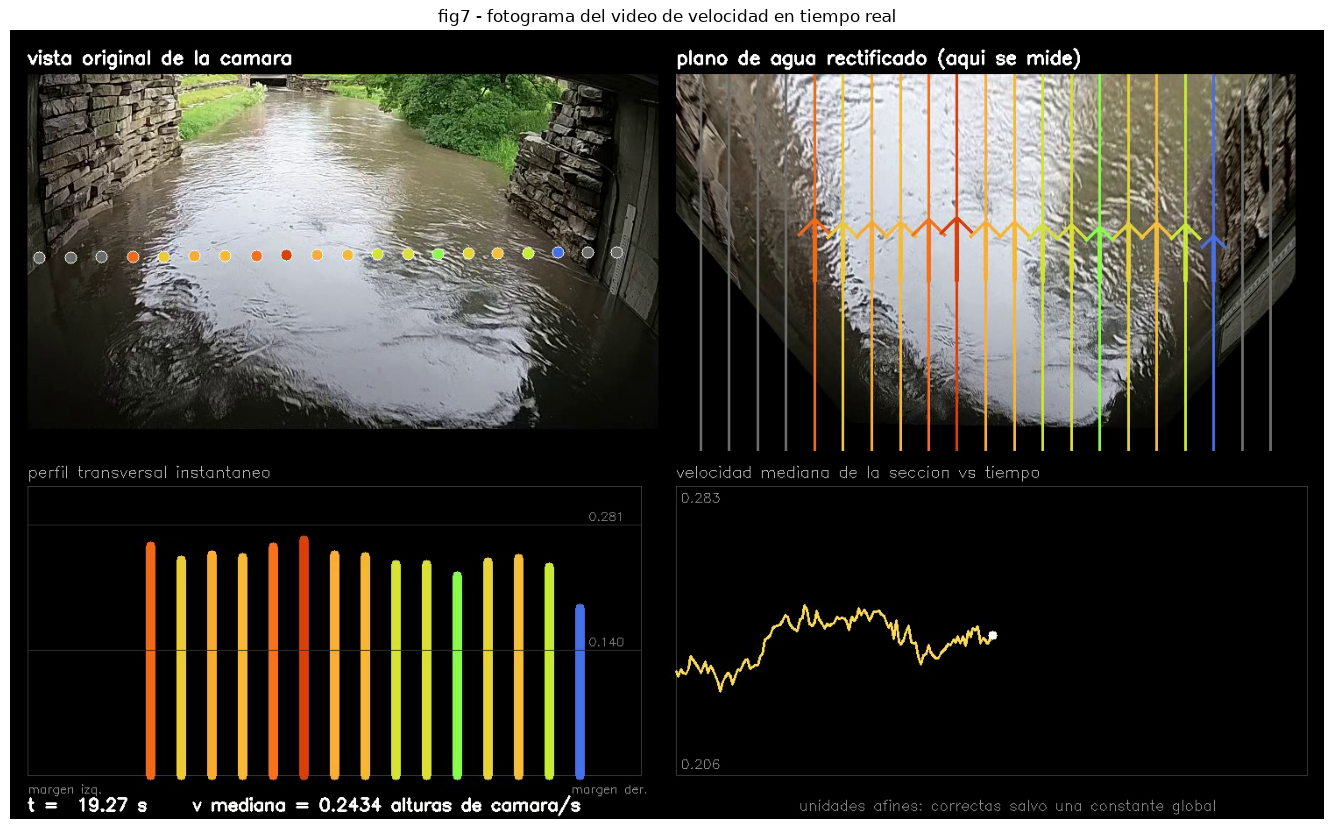

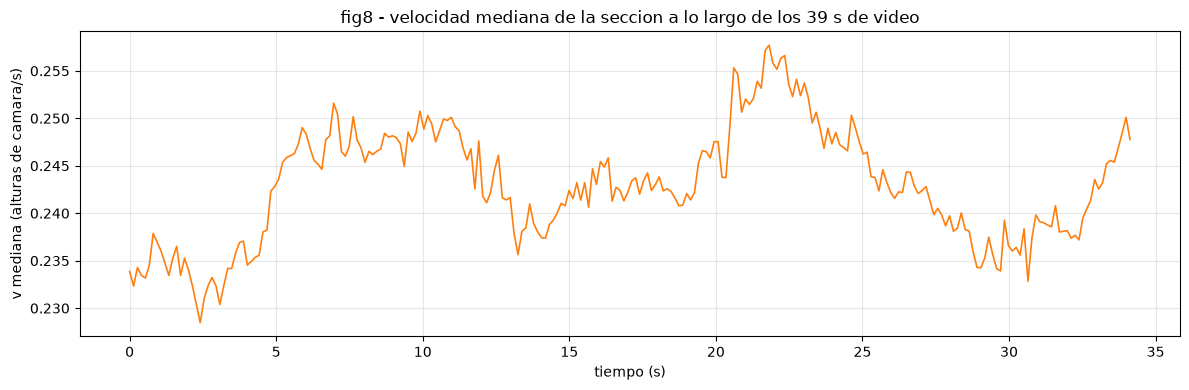

fluctuacion temporal: 0.2285 - 0.2577 (+-6.0% alrededor de la mediana)


In [22]:
salida_video = os.path.join(DIR_SALIDA, 'velocidad_tiempo_real.mp4')
if os.path.exists(salida_video):
    cap = cv2.VideoCapture(salida_video)
    n_v, fps_v = cap.get(cv2.CAP_PROP_FRAME_COUNT), cap.get(cv2.CAP_PROP_FPS)
    cap.set(cv2.CAP_PROP_POS_FRAMES, n_v // 2)
    ok, fr = cap.read()
    cap.release()
    print(f'{salida_video}: {n_v:.0f} fotogramas a {fps_v:.2f} fps '
          f'({n_v/fps_v:.0f} s, {os.path.getsize(salida_video)/1e6:.0f} MB)')
    fig, ax = plt.subplots(figsize=(14, 8.4))
    ax.imshow(cv2.cvtColor(fr, cv2.COLOR_BGR2RGB)); ax.axis('off')
    ax.set_title('fig7 - fotograma del video de velocidad en tiempo real')
    fig.tight_layout(); fig.savefig(os.path.join(DIR_SALIDA, 'fig7_video_muestra.png'), dpi=110)
    plt.show()

# la serie temporal que el video dibuja, tambien como dato
ruta_np = os.path.join(DIR_SALIDA, 'velocidad_ventanas.npy')
if os.path.exists(ruta_np):
    Vv = np.load(ruta_np)
    vt = np.nanmedian(np.abs(Vv), axis=1)
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(np.arange(len(vt)) * 3 / FPS, vt, lw=1.2, color='tab:orange')
    ax.set_xlabel('tiempo (s)'); ax.set_ylabel('v mediana (alturas de camara/s)')
    ax.set_title(f'fig8 - velocidad mediana de la seccion a lo largo de los '
                 f'{N_TOTAL/FPS:.0f} s de video')
    ax.grid(alpha=0.3)
    fig.tight_layout(); fig.savefig(os.path.join(DIR_SALIDA, 'fig8_serie_temporal.png'), dpi=110)
    plt.show()
    print(f'fluctuacion temporal: {np.nanmin(vt):.4f} - {np.nanmax(vt):.4f} '
          f'(+-{100*(np.nanmax(vt)-np.nanmin(vt))/2/np.nanmedian(vt):.1f}% alrededor de la mediana)')

## Limitaciones conocidas

1. **No hay caudal, y no es un descuido.** Falta una longitud real y falta la seccion. Todo lo que
   se reporta esta en unidades afines. La via para cerrarlo son las mediciones de campo de NWIS
   para la estacion 03337000.
2. **Balanceo nulo es una hipotesis, no una medida.** El punto de fuga vertical se intento estimar
   y salio absurdo, asi que el horizonte se apoya en que la camara este a nivel. Un balanceo de un
   grado inclinaria el horizonte y sesgaria la rectificacion.
3. **La distorsion de lente no se corrige.** Es una camara bullet gran angular con barril visible.
   Se decidio no corregirla porque la rectificacion se autovalida —si importara, el canal saldria
   combado en fig3— pero eso es una comprobacion visual, no una cota. Un ajuste de plomada por
   barrido de k1 se intento y fallo: premiaba el artefacto de barrido radial de la sobrecorreccion.
4. **La mitad lejana del campo no se mide.** Cerca del horizonte un pixel cubre demasiado terreno y
   el remuestreo borra la textura; medido, la correlacion cae de 0.78 a 0.32. Por eso `YMAX = 2.80`.
5. **Las estaciones junto a los muros son las mas debiles**, como en el caso SMC. Cobertura parcial
   y contraste bajo. El maximo del perfil cae junto a la margen izquierda, lo cual es fisicamente
   sospechoso y probablemente sea contaminacion de muro, no flujo real.
6. **Solo un video.** El valor real del dataset son 50 videos diurnos entre 94 y 368 cfs, con los
   que se podria contrastar la velocidad medida contra Q en todo el rango. Eso es lo que este caso
   deja preparado y no hace.
7. **El escalon de camara entre 2017 y 2018** (~1 px en dy, medido en la Parte 1) es despreciable
   para un video suelto, pero habria que tenerlo en cuenta al procesar la serie completa.

## Equivalencia con los otros casos del workspace

| Etapa | `analisis_USGS_SMC_stiv` | Este notebook |
|---|---|---|
| Estabilizacion | `estabilizar_stiv.py`, 1.1 GB previos | no hace falta (medido: 0.06 px) |
| Escala | 2 filas a mano -> 1.7790 mm/px | punto de fuga -> afinidad, sin metros |
| Vista | cenital, escala uniforme | oblicua, hay que rectificar |
| Linea de flujo | recta inclinada `ANGULO_FLUJO` | columna del plano rectificado |
| Antialias | `sigma = DS/2`, isotropo | igual |
| Tensor | bloques 64, solape 50% | bloques 48, solape 50% |
| Filtro QC | coherencia > 0.70 | contraste temporal > 1.5 (la coherencia *aprueba* los muros) |
| Relleno | interpolacion lineal a los ceros de muro | ninguno: se declaran huecos |
| Resultado | Q = 1.2221 m3/s vs 1.4362 aforo (-14.9%) | v superficial en unidades afines, sin Q |